# 01 — EDA: memahami data sebelum pelabelan

**Tujuan:** memahami isi `data/raw/comments_cleaned.csv` untuk memutuskan **skema label** dan **cara pelabelan** (dataset ini belum berlabel).

Alur: struktur data → panjang komentar → kualitas & duplikasi teks → pola kata → indikator tema (regex kasar) → estimasi awal dari membaca sampel → kesimpulan untuk pelabelan.

> Semua angka dihitung ulang dari data mentah setiap notebook dijalankan, **kecuali** bagian 6 (*estimasi dari membaca sampel*) yang merupakan hasil pembacaan manual.

In [1]:
import re, unicodedata, collections
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw" / "comments_cleaned.csv"
FIG = ROOT / "results" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

# Gaya grafik: satu hue biru untuk magnitudo, abu-abu untuk "tidak terdeteksi/lainnya"
SURFACE, INK, INK2, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7"
BLUE, GRAY = "#2a78d6", "#c3c2b7"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.edgecolor": AXIS, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 10, "figure.dpi": 110,
})
pd.set_option("display.max_colwidth", 120)

def hbar(ax, labels, values, fmt="{:,.0f}", colors=BLUE, xmax=None, label_x=None):
    """Bar horizontal dengan label nilai di ujung batang (atau di label_x bila ada garis galat)."""
    y = np.arange(len(labels))[::-1]
    ax.barh(y, values, height=0.6, color=colors)
    ax.set_yticks(y, labels)
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", length=0)
    top = xmax or max(values) * 1.18
    ax.set_xlim(0, top)
    xs = values if label_x is None else label_x
    for yi, v, x in zip(y, values, xs):
        ax.text(x + top * 0.012, yi, fmt.format(v), va="center", ha="left", color=INK2, fontsize=9)

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / name, dpi=150)
    plt.show()

## 1. Struktur data

In [2]:
df = pd.read_csv(RAW, dtype=str)
df["n_words"] = df.text_clean.str.split().str.len()

print("bentuk data      :", df.shape, "| kolom:", list(df.columns))
print("nilai kosong     :", int(df.isna().sum().sum()))
print("comment_id unik  :", df.comment_id.is_unique)
print("teks identik persis (duplikat mentah):", int(df.text_clean.duplicated().sum()))

per_post = (df.groupby("post_id")
              .agg(komentar=("text_clean", "size"), median_kata=("n_words", "median"),
                   rerata_kata=("n_words", "mean"), maks_kata=("n_words", "max"))
              .sort_values("komentar", ascending=False).round(1))
per_post["porsi_%"] = (per_post.komentar / len(df) * 100).round(1)
per_post

bentuk data      : (6566, 4) | kolom: ['post_id', 'comment_id', 'text_clean', 'n_words']
nilai kosong     : 0
comment_id unik  : True
teks identik persis (duplikat mentah): 0


,komentar,median_kata,rerata_kata,maks_kata,porsi_%
post_id,,,,,
DeocT0SHONR,3634,4.0,5.5,65,55.3
DerdfZLHCLn,2703,5.0,7.1,248,41.2
DewUDDnggyH,128,9.0,11.2,40,1.9
DewF0WXEeBc,101,8.0,11.8,74,1.5


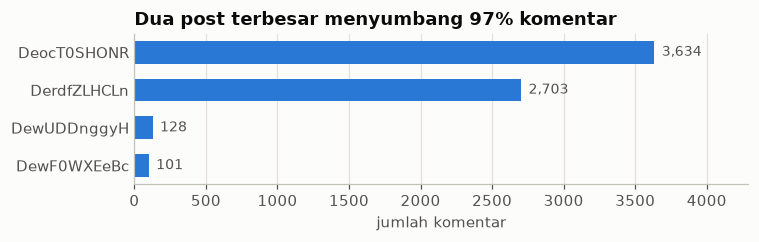

In [3]:
top2 = per_post.komentar.iloc[:2].sum() / len(df) * 100
fig, ax = plt.subplots(figsize=(7, 2.3))
hbar(ax, per_post.index.tolist(), per_post.komentar.tolist())
ax.set_title(f"Dua post terbesar menyumbang {top2:.0f}% komentar")
ax.set_xlabel("jumlah komentar")
save(fig, "eda_01_komentar_per_post.png")

## 2. Panjang komentar

count    6566.0
mean        6.4
std         7.4
min         1.0
25%         3.0
50%         5.0
75%         8.0
90%        12.0
95%        16.0
99%        30.0
max       248.0

1 kata: 11.5% | ≤2 kata: 22.1% | ≤5 kata: 57.4% | ≥20 kata: 3.2%


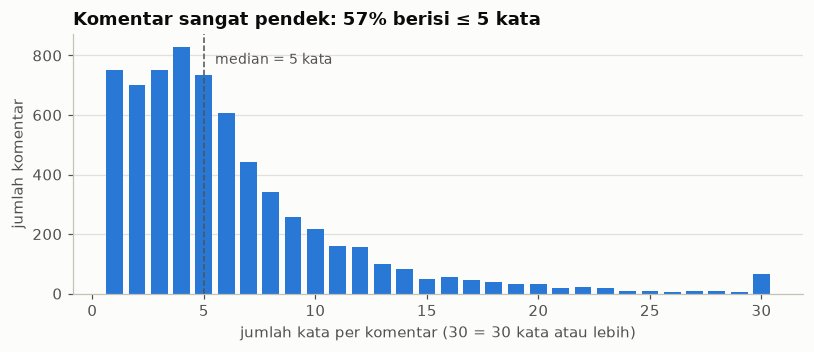

In [4]:
w = df.n_words
print(w.describe(percentiles=[.25, .5, .75, .9, .95, .99]).round(1).to_string())
print(f"\n1 kata: {(w==1).mean():.1%} | ≤2 kata: {(w<=2).mean():.1%} | ≤5 kata: {(w<=5).mean():.1%} | ≥20 kata: {(w>=20).mean():.1%}")

counts = w.clip(upper=30).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7.5, 3.3))
ax.bar(counts.index, counts.values, width=0.75, color=BLUE)
ax.axvline(w.median(), color=INK2, lw=1, ls="--")
ax.text(w.median() + 0.5, counts.max() * 0.93, f"median = {w.median():.0f} kata", color=INK2, fontsize=9)
ax.grid(axis="x", visible=False)
ax.set_xlabel("jumlah kata per komentar (30 = 30 kata atau lebih)")
ax.set_ylabel("jumlah komentar")
ax.set_title(f"Komentar sangat pendek: {(w<=5).mean():.0%} berisi ≤ 5 kata")
save(fig, "eda_02_panjang_komentar.png")

## 3. Kualitas teks & duplikasi

In [5]:
def norm(s, collapse=True):
    """NFKC (memperbaiki font hias), huruf kecil, buang tanda baca, rapikan huruf berulang."""
    s = unicodedata.normalize("NFKC", s).lower()
    s = re.sub(r"[^a-z0-9\s]", " ", s)
    if collapse:
        s = re.sub(r"(.)\1+", r"\1", s)              # 'caiiirrr' -> 'cair'
    return re.sub(r"\s+", " ", s).strip()

df["lite"] = df.text_clean.map(lambda s: norm(s, collapse=False))   # untuk n-gram
df["norm"] = df.text_clean.map(norm)                                 # untuk deteksi duplikat
fancy = df.text_clean != df.text_clean.map(lambda s: unicodedata.normalize("NFKC", s))

feat = {
    "mengandung '?'": df.text_clean.str.contains(r"\?"),
    "mengandung '!'": df.text_clean.str.contains("!"),
    "huruf berulang ≥3x ('caiiirrr')": df.text_clean.map(lambda s: bool(re.search(r"(.)\1{2,}", s))),
    "mengandung angka": df.text_clean.str.contains(r"\d"),
    "tertawa (wkwk/haha/hehe)": df.text_clean.str.lower().str.contains(r"w+k+w*k+|ha(?:ha)+|he(?:he)+|kwk"),
    "SEMUA HURUF KAPITAL": df.text_clean.map(str.isupper),
    "karakter non-ASCII (emoji/lainnya)": df.text_clean.str.contains(r"[^\x00-\x7F]"),
    "font hias Unicode (butuh NFKC)": fancy,
    "mention / URL / hashtag": df.text_clean.str.contains(r"@\w+|https?://|www\.|#\w+"),
}
print((pd.Series({k: v.mean() * 100 for k, v in feat.items()}).round(1).astype(str) + " %").to_string())

vc = df.norm.value_counts()
dup_rows = int((df.norm.map(vc) > 1).sum())
print(f"\nunik setelah normalisasi        : {df.norm.nunique():,} dari {len(df):,}")
print(f"baris yang punya 'kembaran'     : {dup_rows} ({dup_rows/len(df):.1%})")
print(f"kosong setelah normalisasi      : {int((df.norm == '').sum())}  (hanya simbol / '?' / karakter rusak)")
vc.drop("", errors="ignore").head(12).to_frame("jumlah")

mengandung '?'                        18.8 %
mengandung '!'                         3.3 %
huruf berulang ≥3x ('caiiirrr')       25.2 %
mengandung angka                      11.7 %
tertawa (wkwk/haha/hehe)               4.2 %
SEMUA HURUF KAPITAL                    6.0 %
karakter non-ASCII (emoji/lainnya)     2.2 %
font hias Unicode (butuh NFKC)         1.8 %
mention / URL / hashtag                0.2 %



unik setelah normalisasi        : 6,013 dari 6,566
baris yang punya 'kembaran'     : 776 (11.8%)
kosong setelah normalisasi      : 6  (hanya simbol / '?' / karakter rusak)


,jumlah
norm,
pret,34
hah,21
bhap,19
mungken,16
cair,14
masyarakat yg mana,13
hoax,12
masyarakat yang mana,12
cuih,12


## 4. Pola kata dan kalimat

kosakata: 7,087 kata unik dari 41,683 token; 62% kata unik hanya muncul sekali (fitur sangat jarang/sparse)


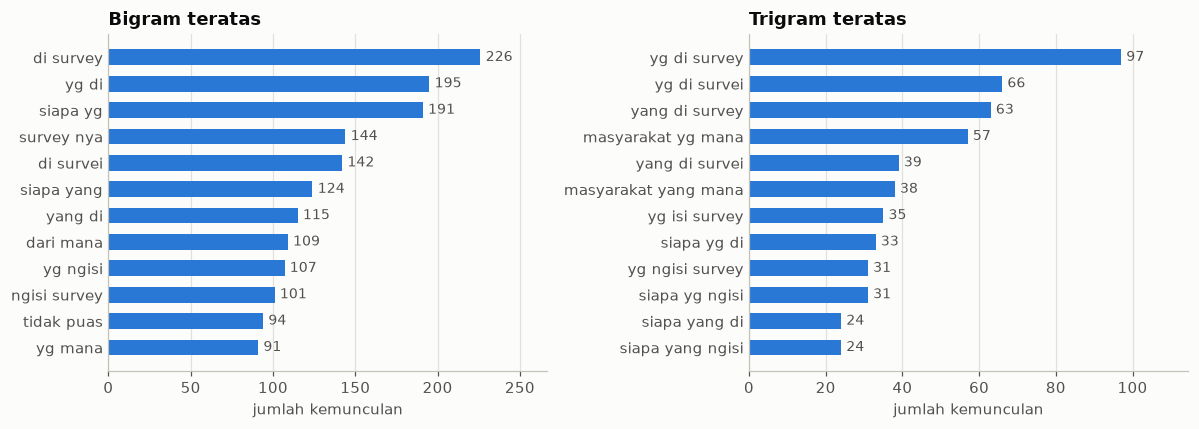

In [6]:
def ngrams(texts, n):
    c = collections.Counter()
    for s in texts:
        w_ = s.split()
        c.update(" ".join(w_[i:i + n]) for i in range(len(w_) - n + 1))
    return c

words = collections.Counter(t for s in df.lite for t in s.split())
hapax = sum(1 for c in words.values() if c == 1)
print(f"kosakata: {len(words):,} kata unik dari {sum(words.values()):,} token; "
      f"{hapax/len(words):.0%} kata unik hanya muncul sekali (fitur sangat jarang/sparse)")

bi, tri = ngrams(df.lite, 2).most_common(12), ngrams(df.lite, 3).most_common(12)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, data, title in zip(axes, (bi, tri), ("Bigram teratas", "Trigram teratas")):
    hbar(ax, [g for g, _ in data], [c for _, c in data])
    ax.set_title(title); ax.set_xlabel("jumlah kemunculan")
save(fig, "eda_03_ngram.png")

## 5. Indikator tema (regex kasar)

Ini **bukan label**. Hanya pendeteksi kata kunci untuk gambaran awal. Hasilnya dibandingkan dengan estimasi membaca sampel di bagian 6 untuk melihat seberapa jauh kata kunci bisa dipercaya.

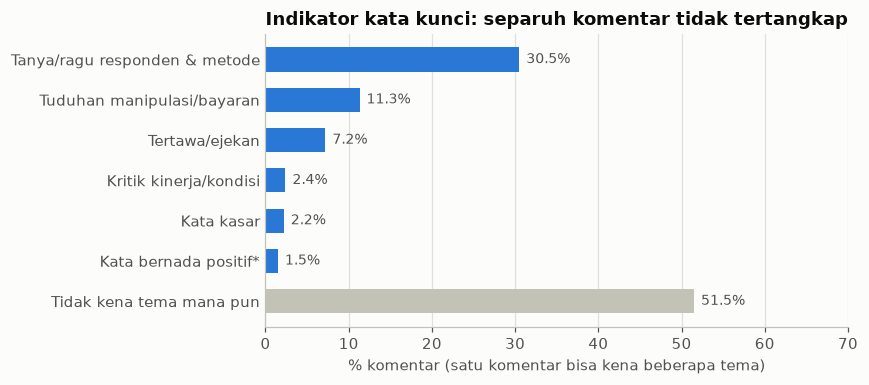

* termasuk komentar sarkastik, jadi 'positif' di sini TIDAK berarti mendukung.

% komentar per post:


,Tanya/ragu responden & metode,Tuduhan manipulasi/bayaran,Kritik kinerja/kondisi,Tertawa/ejekan,Kata kasar,Kata bernada positif*,n
post_id,,,,,,,
DeocT0SHONR,28.5,10.0,1.7,7.9,2.3,1.3,3634
DerdfZLHCLn,34.4,12.8,2.7,6.4,2.0,1.5,2703
DewF0WXEeBc,19.8,15.8,8.9,5.9,2.0,4.0,101
DewUDDnggyH,12.5,14.1,8.6,4.7,3.1,3.9,128



Jumlah komentar yang menyebut lembaga/media (penciri tiap post):


,ppi,poltracking,smrc,tempo,kumparan,indikator,litbang
post_id,,,,,,,
DeocT0SHONR,51,0,1,1,111,0,0
DerdfZLHCLn,0,17,1,0,0,0,0
DewF0WXEeBc,2,2,2,3,0,0,0
DewUDDnggyH,11,0,7,0,0,0,0


In [7]:
low = df.text_clean.map(lambda s: unicodedata.normalize("NFKC", s).lower())
THEMES = {
 "Tanya/ragu responden & metode": r"(?:siapa|\bsapa\b|\bmana\b|\bmane\b|\bmna\b|darimana|\bkapan\b|responden|sample|sampel|ngisi|nyurvei|disurvei|disurvey|di survei|di survey|pernah (?:isi|ikut|disurvei|dapat|dapet|kebagian)|(?:ga|gak|nggak|tidak|ngga|gk) (?:pernah|ikut|ngisi|isi))",
 "Tuduhan manipulasi/bayaran":   r"(?:buzzer|bayar|dibayar|byr|\bcair\b|\bspj\b|pesanan|rekayasa|manipulasi|hoax|hoaks|bohong|ngibul|ngarang|karangan|palsu|pencitraan|setingan|settingan|diorder|\border\b|diatur|atur aja|bodong|ghoib|gaib|goib|fiktif|siluman|konoha|amplop|suap|jilat|penjilat)",
 "Kritik kinerja/kondisi":       r"(?:\bdemo\b|ekonomi|susah|sengsara|lengser|mundur|gagal|korupsi|\bphk\b|pajak|harga|miskin|kecewa|menyesal|hancur|berantakan|bubar|makzul|keracunan|kopdes|janji|nyusahin|bancakan|\bkkn\b)",
 "Tertawa/ejekan":               r"(?:wk|haha|hehe|kwk|ngakak|lucu|kocak|zonk|\bdih\b|preet|pret\b|cocote|karepmu|halu)",
 "Kata kasar":                   r"(?:anjing|anjg|\bajg\b|bangsat|goblok|tolol|bodoh|bego|\btai\b|taik|kontol|kntl|memek|\basu\b|jancok|jancuk|bajingan|sampah|dungu|idiot|kampret|brengsek|sinting|\bbabi\b|monyet|iblis|setan|berak|ndas)",
 "Kata bernada positif*":        r"(?:mantap|mantab|mantul|bagus|keren|hebat|setuju|lanjutkan|sukses|terima ?kasih|makasih|semangat|bangga|aamiin|\bamin\b|dukung|luar biasa|salut)",
}
hit = pd.DataFrame({k: low.str.contains(p, regex=True) for k, p in THEMES.items()})
share = (hit.mean() * 100).sort_values(ascending=False)
none = 100 - hit.any(axis=1).mean() * 100

labels = share.index.tolist() + ["Tidak kena tema mana pun"]
vals = share.round(1).tolist() + [round(none, 1)]
cols = [BLUE] * len(share) + [GRAY]
fig, ax = plt.subplots(figsize=(8, 3.6))
hbar(ax, labels, vals, fmt="{:.1f}%", colors=cols, xmax=70)
ax.set_title("Indikator kata kunci: separuh komentar tidak tertangkap")
ax.set_xlabel("% komentar (satu komentar bisa kena beberapa tema)")
save(fig, "eda_04_indikator_tema.png")
print("* termasuk komentar sarkastik, jadi 'positif' di sini TIDAK berarti mendukung.")

print("\n% komentar per post:")
display((hit.groupby(df.post_id).mean() * 100).round(1).assign(n=df.post_id.value_counts()))

inst = ["ppi", "poltracking", "smrc", "tempo", "kumparan", "indikator", "litbang"]
print("\nJumlah komentar yang menyebut lembaga/media (penciri tiap post):")
display(pd.DataFrame({k: low.str.contains(r"\b" + k).groupby(df.post_id).sum() for k in inst}))

## 6. Estimasi awal dengan membaca sampel

Satu sampel acak (`df.sample(120, random_state=2026)`) dibaca dan dikelompokkan secara manual memakai **skema kandidat 6 kelas**. Dibaca oleh Claude (AI), **hanya untuk memandu desain skema**. Ini bukan label resmi dan **tidak disimpan** di `data/labeled/`. Dengan n = 120, rentang kepercayaannya lebar, jadi gunakan sebagai gambaran kasar. Sekitar 10% (12 dari 120) komentar terasa ambigu antar kelas.

| Kelas | Definisi singkat | Contoh |
|---|---|---|
| **TANYA** | mempertanyakan/meragukan siapa, di mana, kapan responden & metode (termasuk "saya tidak pernah disurvei") | "Masyarakat mana?", "Yang di survey siapa?" |
| **TUDUH** | menyatakan survei dibayar/dipesan/direkayasa/respondennya orang pemerintah | "Survey bayaran", "yg ngisi pegawai MBG semua" |
| **KRITIK** | menolak hasil / menyatakan ketidakpuasan dengan alasan kondisi, kinerja pemerintah, atau media | "100% rakyat kecewa", "Lebih baik tutup akun aja min" |
| **REAKSI** | reaksi emosional, ejekan, umpatan, tawa tanpa informasi | "Puas ndasmu", "wkwkwk", "pret" |
| **DUKUNG** | mendukung pemerintah/survei atau membela hasilnya | "Pembenci ramenya di medsos doang" |
| **LAIN** | netral, informasi, tidak terkait, atau tak dapat ditentukan | "Prabowo gibran", "Hemmmzzz.." |

,kelas,n,persen,ci95_bawah,ci95_atas
0,TANYA,36,30.0,22.5,38.7
1,TUDUH,33,27.5,20.3,36.1
2,REAKSI,24,20.0,13.8,28.0
3,KRITIK,19,15.8,10.4,23.4
4,LAIN,5,4.2,1.8,9.4
5,DUKUNG,3,2.5,0.9,7.1


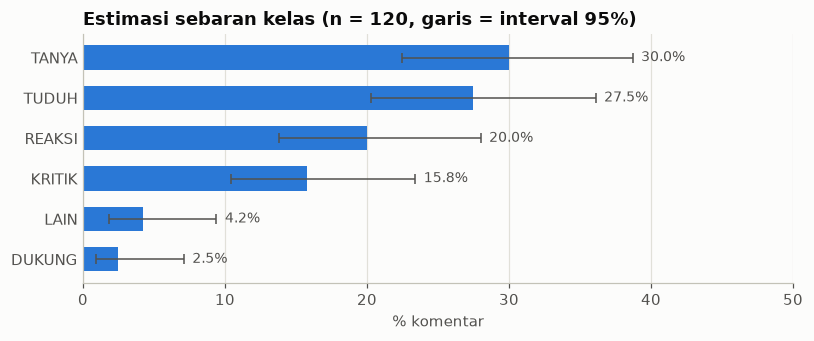

In [8]:
est = pd.DataFrame({"kelas": ["TANYA", "TUDUH", "REAKSI", "KRITIK", "LAIN", "DUKUNG"],
                    "n": [36, 33, 24, 19, 5, 3]})
N = int(est.n.sum())

def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return c - h, c + h

est["persen"] = (est.n / N * 100).round(1)
ci = est.n.map(lambda k: wilson(k, N))
est["ci95_bawah"] = [round(a * 100, 1) for a, _ in ci]
est["ci95_atas"] = [round(b * 100, 1) for _, b in ci]
display(est)

fig, ax = plt.subplots(figsize=(7.5, 3.2))
hbar(ax, est.kelas.tolist(), est.persen.tolist(), fmt="{:.1f}%", xmax=50, label_x=est.ci95_atas.tolist())
y = np.arange(len(est))[::-1]
ax.errorbar(est.persen, y, xerr=[est.persen - est.ci95_bawah, est.ci95_atas - est.persen],
            fmt="none", ecolor=INK2, elinewidth=1, capsize=3)
ax.set_title(f"Estimasi sebaran kelas (n = {N}, garis = interval 95%)")
ax.set_xlabel("% komentar")
save(fig, "eda_05_estimasi_kelas.png")

## 7. Kesimpulan untuk pelabelan

1. **Topik sebenarnya:** komentar atas pemberitaan *survei kepuasan publik terhadap pemerintah* (4 post, dua di antaranya ±97% data). Hanya ~1,5% komentar menyebut MBG. Isinya soal **kredibilitas survei**, bukan MBG.
2. **Sentimen positif/netral/negatif kurang cocok sebagai target.** Hampir semua komentar negatif atau skeptis. Dukungan eksplisit hanya ±3% (CI kira-kira 1–7%), dan banyak "pujian" ternyata sarkasme. Model yang selalu menebak "negatif" sudah akurat >90%, sehingga membandingkan ANN/SVM/Ensemble/Bayesian menjadi tidak informatif.
3. **Skema yang disarankan:** *jenis reaksi terhadap hasil survei* (TANYA, TUDUH, KRITIK, REAKSI, DUKUNG, LAIN). Estimasi sebaran ≈ 30 / 28 / 16 / 20 / 3 / 4 %. **Label sehalus mungkin dulu, gabungkan kelas kecil saat modeling**, karena kelas yang sudah digabung tidak bisa dipecah lagi.
4. **Kata kunci tidak cukup untuk melabel otomatis.** Regex hanya cocok untuk TANYA (±30%, sejalan dengan estimasi). Ia sangat kurang menangkap TUDUH dan KRITIK, dan salah membaca sarkasme. Pelabelan harus manual oleh manusia.
5. **Siapkan data sebelum dibagikan ke pelabel:** terapkan NFKC (±120 komentar memakai font hias), buang komentar kosong (hanya simbol/`?`), dan kumpulkan teks kembar (±12% baris punya kembaran) supaya satu teks dilabel sekali saja. Sisa ±6.000 teks unik.
6. **Prosedur:** panduan label tertulis dengan aturan prioritas dan contoh kasus sulit (sarkasme, pertanyaan retoris, kalimat campuran) → *pilot* ±150 komentar dilabel bersama → hitung kappa (Cohen/Fleiss) dan revisi panduan → baru bagi sisanya, dengan ±10% tumpang tindih untuk memantau kesepakatan.
7. **Catatan untuk tahap modeling:** pisahkan train/test berdasarkan kelompok teks kembar (hindari kebocoran), laporkan **macro-F1** dan hasil per kelas (bukan hanya akurasi), dan pertimbangkan uji lintas-post (latih di satu post, uji di post lain) sebagai bahan diskusi paper.